In [13]:
from dotenv import load_dotenv
from pydantic import BaseModel, Field

'''
Sequence: Automatically handles the state updates for sequences such as by 
adding new messages to a chat history
'''
from typing import Annotated, Sequence

from IPython.display import Image, display

from langchain_core.tools import tool
from langchain.schema.runnable import RunnableSequence
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.output_parsers import StrOutputParser

'''
BaseMessage: The foundational class for all messages in LangGraph

ToolMessage: Passes data back to LLM after it calls a tool 
such as the content and the tool_call_id

SystemMessage: Provides instructions to the LLM
'''
from langchain_core.messages import BaseMessage, ToolMessage, SystemMessage

from langgraph.prebuilt import ToolNode
from langgraph.graph import StateGraph, END

'''
add_messages: Reducer function

- Rule that controls how updates from nodes are combined with the existing 
state
- Tells us how to merge new data into the current state
- Without a reducer, updates would have replaced the existing value entirely!
'''
from langgraph.graph.message import add_messages

In [14]:
load_dotenv()

True

In [15]:
class AgentState(BaseModel):
    # the following attempts to append messages rather than replacing 
    # the existing ones
    messages: Annotated[
        Sequence[BaseMessage], 
        add_messages, 
        Field(
        description="A list of prompts given by the user (human) and the corresponding response given by the AI  assistant"
    )]

In [16]:
@tool
def add(a: int, b: int) -> int:
    """
    Returns the sum of 2 integers
    
    Parameters:
        - a: integer: The first integer
        - b: integer: The first integer

    Returns:
        - integer
    """

    return a + b


@tool
def subtract(a: int, b: int) -> int:
    """
    Returns the difference between 2 integers
    
    Parameters:
        - a: integer: The first integer
        - b: integer: The first integer

    Returns:
        - integer
    """

    return a - b


@tool
def multiply(a: int, b: int) -> int:
    """
    Returns the product of 2 integers
    
    Parameters:
        - a: integer: The first integer
        - b: integer: The first integer

    Returns:
        - integer
    """

    return a * b

In [17]:
tools = [add, subtract, multiply]

In [18]:
# the llm now has access to all the tools
llm = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash",
    temperature=0.6
).bind_tools(tools)
chain = RunnableSequence(llm, StrOutputParser())

In [20]:
def modelCall(state: AgentState) -> AgentState:
    systemPrompt = SystemMessage(content=
        "You are an AI assistant. Please answer any query to the best of your ability."
    )
    response = chain.invoke([systemPrompt] + state["messages"])

    return {"messages": [response]}


def shouldContinue(state: AgentState): 
    messages = state["messages"]
    last_message = messages[-1]
    if not last_message.tool_calls: 
        return "end"
    else:
        return "continue"

In [21]:
graph = StateGraph(AgentState)
graph.add_node("agent", modelCall)

tool_node = ToolNode(tools=tools)  # a node that contains all the tools
graph.add_node("tools", tool_node)

graph.set_entry_point("agent")

graph.add_conditional_edges(
    "agent",
    shouldContinue,
    {
        "continue": "tools",
        "end": END,
    },
)

graph.add_edge("tools", "agent")

app = graph.compile()

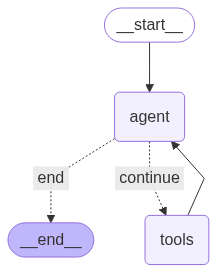

In [22]:
display(Image(app.get_graph().draw_mermaid_png()))

In [25]:
def printStream(stream):
    for s in stream:
        message = s["messages"][-1]
        if isinstance(message, tuple):
            print(message)
        else:
            message.pretty_print()

In [26]:
inputs = {"messages": [("user", "Add 3 + 4")]}
printStream(app.stream(inputs, stream_mode="values"))

ValidationError: 1 validation error for AgentState
messages.0
  Input should be a valid dictionary or instance of BaseMessage [type=model_type, input_value=('user', 'Add 3 + 4'), input_type=tuple]
    For further information visit https://errors.pydantic.dev/2.11/v/model_type